In [1]:
import torch
import matplotlib.pyplot as plt
from inc.model import train, save
from inc.networks import LRMCNet

# testing lrmc
from lrmc_generated_data_theoretical_model import lrmc
from inc.synthetic_data import DataGenerator
from virat_data.dataprocess import VideoFile

In [33]:
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
p = 0.1
r = 2
data = VideoFile(device, p, max_frame=1000)
X_orig, Y, omega = data.new()

Iteration: 0, Error: 0.900426983833313, Time: 0.014289140701293945
Iteration: 1, Error: 0.6040605306625366, Time: 0.02531909942626953
Iteration: 2, Error: 0.3819100856781006, Time: 0.03596234321594238
Iteration: 3, Error: 0.21808460354804993, Time: 0.04658317565917969
Iteration: 4, Error: 0.1279739886522293, Time: 0.0572972297668457
Iteration: 5, Error: 0.09222488105297089, Time: 0.06838798522949219
Iteration: 6, Error: 0.08018761873245239, Time: 0.0792088508605957
Iteration: 7, Error: 0.07621873170137405, Time: 0.08989429473876953
Iteration: 8, Error: 0.07528547942638397, Time: 0.10054445266723633
Iteration: 9, Error: 0.07561163604259491, Time: 0.1111598014831543
Iteration: 10, Error: 0.07524794340133667, Time: 0.13663005828857422
Iteration: 11, Error: 0.074516661465168, Time: 0.1629772186279297
Iteration: 12, Error: 0.07396086305379868, Time: 0.1786952018737793
Iteration: 13, Error: 0.07360914349555969, Time: 0.20266056060791016
Iteration: 14, Error: 0.07339148968458176, Time: 0.2286

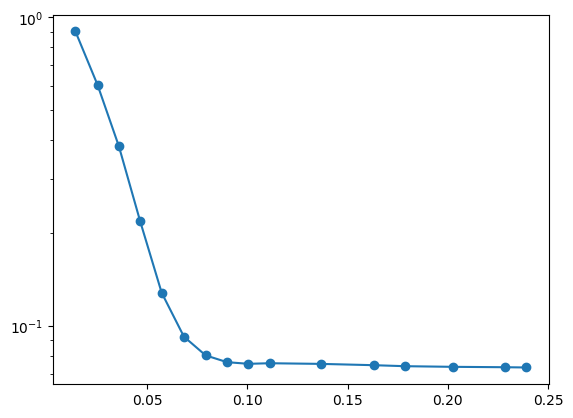

In [34]:
max_iter = 16
zeta = torch.max(torch.abs(X_orig))*0.66**torch.arange(0,max_iter,1, device=device)
eta = torch.ones(max_iter, device=device)/p
eta[:8] = torch.linspace(1, 1 / p, 8) * 0.5
errors, times = lrmc(X_orig, Y, r, omega, zeta, eta, max_iter, device)

plt.figure()
# mark with o
plt.semilogy(times.detach().numpy(), errors.detach().numpy(), 'o-')
plt.show()

In [35]:
eta

tensor([ 0.5000,  1.1429,  1.7857,  2.4286,  3.0714,  3.7143,  4.3571,  5.0000,
        10.0000, 10.0000, 10.0000, 10.0000, 10.0000, 10.0000, 10.0000, 10.0000],
       device='cuda:1')

In [36]:
zeta

tensor([255.0000, 168.3000, 111.0780,  73.3115,  48.3856,  31.9345,  21.0768,
         13.9107,   9.1810,   6.0595,   3.9993,   2.6395,   1.7421,   1.1498,
          0.7588,   0.5008], device='cuda:1')

Iteration: 0, Error: 0.8001058101654053, Time: 0.14453840255737305
Iteration: 1, Error: 0.4737456142902374, Time: 0.14890217781066895
Iteration: 2, Error: 0.2608261704444885, Time: 0.15320873260498047
Iteration: 3, Error: 0.1278706043958664, Time: 0.1574709415435791
Iteration: 4, Error: 0.06195400655269623, Time: 0.1617426872253418
Iteration: 5, Error: 0.03460037708282471, Time: 0.1659984588623047
Iteration: 6, Error: 0.022442271932959557, Time: 0.17027044296264648
Iteration: 7, Error: 0.016267679631710052, Time: 0.17453551292419434
Iteration: 8, Error: 0.00976543314754963, Time: 0.17880940437316895
Iteration: 9, Error: 0.0069983224384486675, Time: 0.18306541442871094
Iteration: 10, Error: 0.004907318390905857, Time: 0.1873321533203125
Iteration: 11, Error: 0.003373600309714675, Time: 0.19160008430480957
Iteration: 12, Error: 0.002286643488332629, Time: 0.19588041305541992
Iteration: 13, Error: 0.0015366028528660536, Time: 0.20013999938964844
Iteration: 14, Error: 0.0010261492570862174

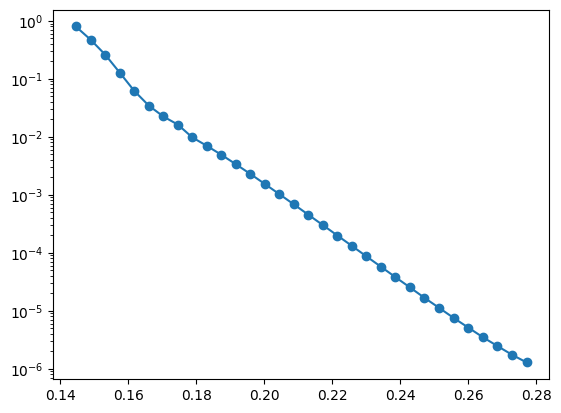

In [2]:
r = 5
n = 5000
d1 = n
d2 = n
alpha = 0.1
p = 0.2
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

data = DataGenerator(d1, d2, r, alpha, p, device)
X_orig, Y, omega = data.new()


max_iter = 32
zeta = torch.max(torch.abs(X_orig))*0.66**torch.arange(0,max_iter,1, device=device)
eta = torch.ones(max_iter, device=device)/p

eta[:8] = torch.linspace(1, 1 / p, 8) * 0.5

errors, times = lrmc(X_orig, Y, r, omega, zeta, eta, max_iter)

plt.figure()
# mark with o
plt.semilogy(times.detach().numpy(), errors.detach().numpy(), 'o-')
plt.show()

In [6]:
import torch 

a = torch.tensor([1.0,2.0,3.0])


In [7]:
m = torch.nn.Softshrink(1.0)
m(a)

tensor([0., 1., 2.])

In [13]:
torch.max(torch.abs(Y))

tensor(0.0036, device='cuda:0')

In [19]:
print(eta)
print(zeta)

tensor([0.5000, 0.7857, 1.0714, 1.3571, 1.6429, 1.9286, 2.2143, 2.5000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000], device='cuda:0')
tensor([3.7803e-03, 2.4950e-03, 1.6467e-03, 1.0868e-03, 7.1731e-04, 4.7342e-04,
        3.1246e-04, 2.0622e-04, 1.3611e-04, 8.9831e-05, 5.9289e-05, 3.9130e-05,
        2.5826e-05, 1.7045e-05, 1.1250e-05, 7.4249e-06, 4.9004e-06, 3.2343e-06,
        2.1346e-06, 1.4089e-06, 9.2984e-07, 6.1370e-07, 4.0504e-07, 2.6733e-07,
        1.7644e-07, 1.1645e-07, 7.6855e-08, 5.0724e-08, 3.3478e-08, 2.2096e-08,
        1.4583e-08, 9.6248e-09], device='cuda:0')


In [20]:
def main(d1, d2, r, alpha, p, max_iter):    
    ths_initial = 18/n
    step_initial = 0.5
    zeta_mult = 0.66
    eta_add = (1/p-step_initial)/7
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

    net = LRMCNet(d1, d2, r, alpha, p, max_iter, ths_initial, step_initial, zeta_mult, eta_add, device)

    nepoch_pre = 500
    nepoch = 500
    lr_init = 0.0001
    net = train(net, nepoch_pre, nepoch, lr_init)
    save(net)

    return net
    

In [21]:
n = 1000    
r = 5
alpha = 0.1
p = 0.2    
max_iter = 16

net = main(n, n, r, alpha, p, max_iter)


# testing lrmc
zeta = net.zeta
eta = net.eta

errors, times = lrmc(X_orig, Y, r, omega, zeta, eta, max_iter)
plt.figure()
plt.semilogy(times.detach().numpy(), errors.detach().numpy(), 'o-')
plt.show()

Layer 1 Pre-training ========================
Pretrain: Layer 1 Epoch 0: Loss 0.8021193742752075
Pretrain: Layer 1 Epoch 100: Loss 0.8021102547645569
Pretrain: Layer 1 Epoch 200: Loss 0.8032727241516113
Pretrain: Layer 1 Epoch 300: Loss 0.8029802441596985
Pretrain: Layer 1 Epoch 400: Loss 0.8021106719970703
tensor(0.0180, device='cuda:0')
tensor(0.5000, device='cuda:0')
Layer 1 Full Training ========================
Layer 2 Pre-training ========================
Pretrain: Layer 2 Epoch 0: Loss 0.3229202926158905
Pretrain: Layer 2 Epoch 100: Loss 0.32181426882743835
Pretrain: Layer 2 Epoch 200: Loss 0.32747653126716614
Pretrain: Layer 2 Epoch 300: Loss 0.3244578540325165
Pretrain: Layer 2 Epoch 400: Loss 0.3212701082229614
tensor(0.0119, device='cuda:0')
tensor(1.1429, device='cuda:0')
Layer 2 Full Training ========================
Fulltrain: Layer 2 Epoch 0: Loss 0.32217222452163696
Fulltrain: Layer 2 Epoch 100: Loss 0.3197180926799774
Fulltrain: Layer 2 Epoch 200: Loss 0.31862998008728

KeyboardInterrupt: 